# Chapter 23: Information Acquisition, Disclosure, Persuasion, and Attention

This notebook reruns four worked examples from the chapter: a committed disclosure rule (Bayesian persuasion), cheap talk from a biased staff, disclosure that unravels from the top, and the Grossman-Stiglitz limit on informative prices. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def persuasion_concavify(prior, threshold):
    """bayesian-persuasion: sender-optimal binary rule. Always send "retain" in the good state and
    with probability x in the bad state, x = min(1, p(1 - t) / (t(1 - p))), which puts the retain
    posterior at the threshold t. Retention probability = p + (1 - p) x.
    Book (ch023): p = 0.30, t = 0.50 give x = 3/7, retention 0.60, plausibility 0.60(0.50) + 0.40(0)
    = 0.30; t = 0.75 gives x = 1/7 and retention 0.40. Full revelation retains with probability p."""
    if prior >= threshold:
        x = 1.0
    else:
        x = min(1.0, prior * (1 - threshold) / (threshold * (1 - prior)))
    retention = prior + (1 - prior) * x
    post_retain = prior / retention
    post_other = 0.0
    return {"x": x, "retention": retention, "post_retain": post_retain, "post_other": post_other,
            "full_revelation": prior, "no_disclosure": 1.0 if prior >= threshold else 0.0,
            "plausibility": retention * post_retain + (1 - retention) * post_other}


def cheap_talk_two_partition(b):
    """cheap-talk-partition-equilibrium: two-message equilibrium with theta uniform on [0, 1] and
    sender bias b. Boundary condition t + b = (2t + 1) / 4 gives t = (1 - 4b) / 2, a_L = t / 2,
    a_H = (t + 1) / 2. The construction exists only when 0 < t < 1; otherwise babbling, a = 0.50.
    Book (ch023): b = 0.10 gives t = 0.30, a_L = 0.15, a_H = 0.65; b = 0.30 gives t = -0.10."""
    t = (1 - 4 * b) / 2
    exists = 0 < t < 1
    return {"t": t, "exists": exists, "a_L": t / 2 if exists else None,
            "a_H": (t + 1) / 2 if exists else None, "babble": 0.5}


def disclosure_unravel(qualities, fee=0.0, tol=1e-9):
    """disclosure-unraveling: iterate from the top; the best silent seller discloses when
    q - fee > silent price (equally likely types, price = mean of the silent pool). A seller with
    q - fee equal to the silent price is indifferent and is recorded as a tie (treated as silent).
    Book (ch023): {40, 60, 80, 100}, fee 0: 70, 60, 50, then 40 indifferent; fee 15: 100 and 80
    disclose, silent price 50 with {40, 60} silent."""
    silent = sorted(qualities)
    steps, disclosed, tie = [], [], None
    while silent:
        price = sum(silent) / len(silent)
        top = silent[-1]
        net = top - fee
        if net > price + tol:
            steps.append({"q": top, "net": net, "price": price, "discloses": True})
            disclosed.append(top)
            silent = silent[:-1]
        else:
            if abs(net - price) <= tol:
                tie = top
            steps.append({"q": top, "net": net, "price": price, "discloses": False})
            break
    return {"silent": silent, "disclosed": disclosed, "silent_price": sum(silent) / len(silent) if silent else None,
            "steps": steps, "tie": tie}


def info_value_net(pi, v_hi, v_lo, cost):
    """grossman-stiglitz-impossibility: informed trader's profit when prices are informative but
    not fully revealing. Price matches the state with probability pi; rational prices are
    p_high = pi v_hi + (1 - pi) v_lo and p_low = pi v_lo + (1 - pi) v_hi. In either state the
    informed gross profit is pi(v_hi - p_high) + (1 - pi)(v_hi - p_low); net = gross - cost.
    Book (ch023): pi = 0.75 gives prices 110 and 90, 0.75(10) + 0.25(30) = 15, net 13;
    pi = 0.975 gives 0.975(1) + 0.025(39) = 1.95 < 2. (Plan name: finance.gs_informed_profit.)"""
    p_high = pi * v_hi + (1 - pi) * v_lo
    p_low = pi * v_lo + (1 - pi) * v_hi
    gain_match, gain_miss = v_hi - p_high, v_hi - p_low
    gross = pi * gain_match + (1 - pi) * gain_miss
    return {"p_high": p_high, "p_low": p_low, "gain_match": gain_match, "gain_miss": gain_miss,
            "gross": gross, "net": gross - cost, "worthwhile": gross - cost > 0}


plt.rcParams.update(HOUSE_RC)


information = SimpleNamespace(persuasion_concavify=persuasion_concavify, cheap_talk_two_partition=cheap_talk_two_partition, disclosure_unravel=disclosure_unravel, info_value_net=info_value_net)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'bayesian-persuasion': {'prior': 0.3,
                         'threshold': 0.5,
                         'x': 0.42857142857142855,
                         'retention': 0.6,
                         'full_revelation': 0.3,
                         'threshold_high': 0.75,
                         'x_high': 0.14285714285714285,
                         'retention_high': 0.4},
 'cheap-talk-partition-equilibrium': {'b': 0.1,
                                      't': 0.3,
                                      'a_L': 0.15,
                                      'a_H': 0.65,
                                      'b_high': 0.3,
                                      't_high': -0.1,
                                      'babble': 0.5},
 'disclosure-unraveling': {'qualities': (40, 60, 80, 100),
                           'prices_fee0': (70, 60, 50),
                           'fee': 15,
                           'silent_price_fee': 50,
                           'disclosed_fee': (100, 80),
                           'silent_fee': (40, 60)},
 'grossman-stiglitz-impossibility': {'v_hi': 120,
                                     'v_lo': 80,
                                     'cost': 2,
                                     'pi': 0.75,
                                     'prices': (110, 90),
                                     'gross': 15,
                                     'net': 13,
                                     'pi_high': 0.975,
                                     'prices_high': (119, 81),
                                     'gross_high': 1.95},
 'constructed': {'bayesian-persuasion': {'threshold': [0.4, 0.6], 'prior': [0.2, 0.4]},
                 'cheap-talk-partition-equilibrium': {'b': [0.05, 0.2]},
                 'disclosure-unraveling': {'fee': [5, 25]},
                 'grossman-stiglitz-impossibility': {'pi': [0.9]}}}


def persuasion_picture(threshold=0.5, prior=0.3):
    res = information.persuasion_concavify(prior, threshold)
    x, ret = res["x"], res["retention"]
    fig, ax = new_figure()
    vals = [res["full_revelation"], res["no_disclosure"], ret]
    bar_compare(ax, ["Full revelation", "No disclosure", "Optimal rule"], vals, colors=["grey", "gold", "teal"],
                value_labels=[num(v, 2) for v in vals], ylabel="Probability depositors retain funds",
                xlabel="Disclosure policy")
    ax.set_ylim(0, 1.2)
    p, t = num(prior, 2), num(threshold, 2)
    nd = "everyone retains" if res["no_disclosure"] == 1 else "everyone withdraws"
    if prior >= threshold:
        body = (f"The prior {p} already meets the threshold {t}, so no garbling is needed: x = 1 and the retain "
                f"message is always sent. Retention is {p} + {num(1 - prior, 2)}(1) = {num(ret, 2)}.")
        steps = [f"Prior {p} >= threshold {t}, so x = 1", f"Retention = {p} + {num(1 - prior, 2)}(1) = {num(ret, 2)}"]
    else:
        body = (f"Setting {p} / ({p} + {num(1 - prior, 2)}x) = {t} gives x = {p}({num(1 - threshold, 2)}) / "
                f"({t} x {num(1 - prior, 2)}) = {num(x, 4)}. The retain message is sent with probability {p} + "
                f"{num(1 - prior, 2)}({num(x, 5)}) = {num(ret, 4)}, against {p} under full revelation. Bayes "
                f"plausibility: {num(ret, 4)}({t}) + {num(1 - ret, 4)}(0) = {num(res['plausibility'], 4)}.")
        steps = [f"x = {p}({num(1 - threshold, 2)}) / ({t} x {num(1 - prior, 2)}) = {num(x, 4)}",
                 f"Retention = {p} + {num(1 - prior, 2)}({num(x, 5)}) = {num(ret, 4)}",
                 f"Check: {num(ret, 4)}({t}) + {num(1 - ret, 4)}(0) = {num(res['plausibility'], 4)}"]
    metrics = {"Pooling probability x": num(x, 4), "Retention, optimal rule": num(ret, 4),
               "Retention, full revelation": num(prior, 2), "Retention, no disclosure": num(res["no_disclosure"], 0)}
    interp = f"Under no disclosure the posterior stays at {p}, so {nd}. {body}"
    alt = (f"Bars of retention probability: full revelation {p}, no disclosure {num(res['no_disclosure'], 0)}, "
           f"optimal rule {num(ret, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cheap_talk_picture(bias=0.1):
    res = information.cheap_talk_two_partition(bias)
    t = res["t"]
    fig, ax = new_figure()
    ax.plot([0, 1], [0, 0], color=PALETTE["ink"], linewidth=2)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-1, 1.2)
    ax.set_yticks([])
    ax.set_xlabel("Inflation pressure theta")
    ax.set_ylabel("Message region")
    if res["exists"]:
        ax.axvspan(0, t, ymin=0.35, ymax=0.6, color=PALETTE["teal"], alpha=0.25)
        ax.axvspan(t, 1, ymin=0.35, ymax=0.6, color=PALETTE["gold"], alpha=0.25)
        ax.axvline(t, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4)
        label(ax, t, 0.75, f"cutoff t = {num(t, 2)}", col="grey", dx=4)
        for a, name, col in [(res["a_L"], "a_L", "teal"), (res["a_H"], "a_H", "gold")]:
            ax.plot([a], [0], marker="v", markersize=11, color=PALETTE[col])
            label(ax, a, -0.35, f"{name} = {num(a, 2)}", col=col, dx=-20, va="top")
        metrics = {"Cutoff t": num(t, 2), "Action after low": num(res["a_L"], 2), "Action after high": num(res["a_H"], 2),
                   "Two messages informative": "yes"}
        interp = (f"With b = {num(bias, 2)}, the boundary condition t + {num(bias, 2)} = (2t + 1) / 4 gives "
                  f"t = (1 - 4 x {num(bias, 2)}) / 2 = {num(t, 2)}. The committee takes a_L = {num(t, 2)} / 2 = "
                  f"{num(res['a_L'], 3)} after \"low\" and a_H = ({num(t, 2)} + 1) / 2 = {num(res['a_H'], 3)} after "
                  "\"high\".")
        steps = [f"t = (1 - 4 x {num(bias, 2)}) / 2 = {num(t, 2)}", f"a_L = {num(t, 2)} / 2 = {num(res['a_L'], 3)}",
                 f"a_H = ({num(t, 2)} + 1) / 2 = {num(res['a_H'], 3)}"]
    else:
        ax.plot([0.5], [0], marker="v", markersize=11, color=PALETTE["navy"])
        label(ax, 0.5, -0.35, "babbling action 0.50", col="navy", dx=-50, va="top")
        metrics = {"Cutoff t": f"{num(t, 2)} (outside 0 to 1)", "Action after low": "none, messages ignored",
                   "Action after high": "none, messages ignored", "Two messages informative": "no, babbling at 0.50"}
        interp = (f"With b = {num(bias, 2)}, t = (1 - 4 x {num(bias, 2)}) / 2 = {num(t, 2)}, which lies outside "
                  "[0, 1]. The two-message construction fails; the committee ignores messages and chooses the "
                  "prior mean 0.50.")
        steps = [f"t = (1 - 4 x {num(bias, 2)}) / 2 = {num(t, 2)}", "t < 0: no two-interval equilibrium",
                 "Babbling action = 0.50"]
    alt = f"Unit interval of inflation pressure with bias {num(bias, 2)}: " + (
        f"cutoff {num(t, 2)}, actions {num(res['a_L'], 3)} and {num(res['a_H'], 3)}." if res["exists"]
        else "no cutoff, single action 0.50.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def disclosure_picture(fee=15):
    qs = [40, 60, 80, 100]
    res = information.disclosure_unravel(qs, fee)
    fig, ax = new_figure()
    cols = ["navy" if q in res["disclosed"] else "light" for q in qs]
    labels = [f"{q - fee} net" if q in res["disclosed"] else ("indifferent" if q == res["tie"] else "silent")
              for q in qs]
    bar_compare(ax, [f"q = {q}" for q in qs], qs, colors=cols, value_labels=labels, ylabel="Quality and price",
                xlabel="Seller")
    ax.axhline(res["silent_price"], color=PALETTE["gold"], linestyle="dashed", linewidth=1.4,
               label=f"final silent price {num(res['silent_price'], 0)}")
    ax.legend(loc="upper left", frameon=False)
    steps = []
    for s in res["steps"]:
        rel = ">" if s["discloses"] else ("=" if abs(s["net"] - s["price"]) < 1e-9 else "<")
        act = "discloses" if s["discloses"] else ("is indifferent and stays silent" if rel == "=" else "stays silent")
        steps.append(f"Silent price {num(s['price'], 0)}; {s['q']} - {num(fee, 0)} = {num(s['net'], 0)} {rel} "
                     f"{num(s['price'], 0)}, so {s['q']} {act}")
    disc = join_and([str(q) for q in res["disclosed"]]) if res["disclosed"] else "none"
    sil = join_and([str(q) for q in res["silent"]])
    metrics = {"Final silent price": num(res["silent_price"], 0), "Disclosing types": disc, "Silent types": sil}
    interp = (f"With a fee of {num(fee, 0)}: " + "; ".join(steps) + f". The process stops with {sil} silent at a "
              f"price of {num(res['silent_price'], 0)}.")
    alt = (f"Four seller bars with qualities 40 to 100; disclosing types {disc}; final silent price "
           f"{num(res['silent_price'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def gs_picture(pi=0.75):
    res = information.info_value_net(pi, 120, 80, 2)
    fig, ax = new_figure()
    vals = [res["gross"], res["net"]]
    bar_compare(ax, ["Gross profit", "Net of research cost"], vals, colors=["navy", "teal"],
                value_labels=[money(v, 2) for v in vals], ylabel="Expected profit per share ($)",
                xlabel="Informed analyst")
    ax.axhline(2, color=PALETTE["gold"], linestyle="dashed", linewidth=1.4, label="research cost \\$2")
    ax.set_ylim(min(0, res["net"]) - 2, 20)
    ax.legend(loc="upper right", frameon=False)
    p1, q1 = num(pi, 3), num(1 - pi, 3)
    ph, pl = num(res["p_high"], 0), num(res["p_low"], 0)
    gm, gx = num(res["gain_match"], 0), num(res["gain_miss"], 0)
    verdict = ("Research is worthwhile." if res["worthwhile"] else "Research does not pay, so it stops.")
    metrics = {"Prices": f"{ph} and {pl}", "Gross profit": money(res["gross"], 2), "Net profit": money(res["net"], 2),
               "Research worthwhile": "yes" if res["worthwhile"] else "no"}
    interp = (f"Prices are {p1}(120) + {q1}(80) = {ph} and {p1}(80) + {q1}(120) = {pl}. In the high state the analyst "
              f"buys and earns 120 - {ph} = {gm} with probability {p1} or 120 - {pl} = {gx} with probability {q1}: "
              f"{p1}({gm}) + {q1}({gx}) = {num(res['gross'], 2)}. Net of the 2 cost: {num(res['net'], 2)}. {verdict}")
    steps = [f"Prices: {ph} and {pl}", f"Gross = {p1}({gm}) + {q1}({gx}) = {num(res['gross'], 2)}",
             f"Net = {num(res['gross'], 2)} - 2 = {num(res['net'], 2)}"]
    alt = f"Bars for gross profit {num(res['gross'], 2)} and net profit {num(res['net'], 2)} against a research cost of 2."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Bayesian persuasion

$$\frac{0.30}{0.30+0.70x}=0.50\quad\Rightarrow\quad x=\frac{3}{7}, \qquad 0.30+0.70\left(\frac{3}{7}\right)=0.60$$

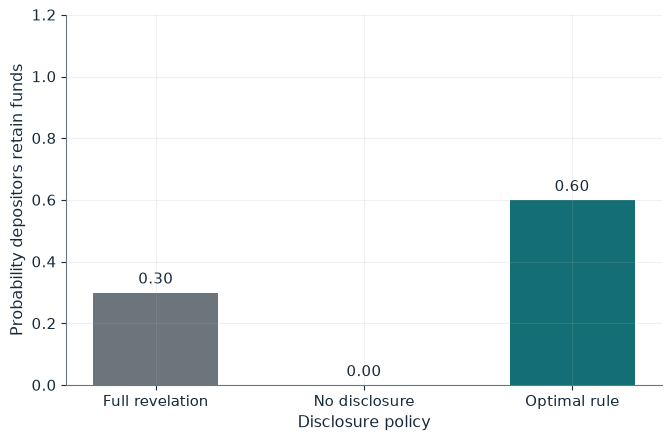

Pooling probability x       0.4286
Retention, optimal rule     0.6000
Retention, full revelation  0.30
Retention, no disclosure    0

Worked steps:
  1. x = 0.30(0.50) / (0.50 x 0.70) = 0.4286
  2. Retention = 0.30 + 0.70(0.42857) = 0.6000
  3. Check: 0.6000(0.50) + 0.4000(0) = 0.3000

Under no disclosure the posterior stays at 0.30, so everyone withdraws. Setting 0.30 / (0.30 + 0.70x) = 0.50 gives x = 0.30(0.50) / (0.50 x 0.70) = 0.4286. The retain message is sent with probability 0.30 + 0.70(0.42857) = 0.6000, against 0.30 under full revelation. Bayes plausibility: 0.6000(0.50) + 0.4000(0) = 0.3000.


In [2]:
show(persuasion_picture(threshold=0.5, prior=0.3))

Change one input, `threshold`, and hold the others at the book's values:

In [3]:
sweep(persuasion_picture, 'threshold', [0.4, 0.5, 0.6, 0.75], {'prior': 0.3}, ['Pooling probability x', 'Retention, optimal rule'])

threshold | Pooling probability x | Retention, optimal rule
0.4 | 0.6429 | 0.7500
0.5 | 0.4286 | 0.6000
0.6 | 0.2857 | 0.5000
0.75 | 0.1429 | 0.4000


The rule doubles retention from 0.30 to 0.60. A stricter threshold of 0.75 allows x = 1/7 and retention 0.40.

## 2. Cheap-talk partition equilibrium

$$t+0.10=\frac{2t+1}{4}, \qquad 4t+0.40=2t+1\quad\Rightarrow\quad t=0.30$$

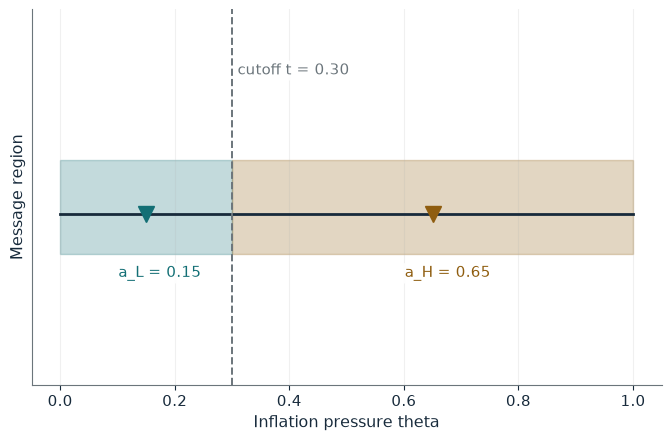

Cutoff t                  0.30
Action after low          0.15
Action after high         0.65
Two messages informative  yes

Worked steps:
  1. t = (1 - 4 x 0.10) / 2 = 0.30
  2. a_L = 0.30 / 2 = 0.150
  3. a_H = (0.30 + 1) / 2 = 0.650

With b = 0.10, the boundary condition t + 0.10 = (2t + 1) / 4 gives t = (1 - 4 x 0.10) / 2 = 0.30. The committee takes a_L = 0.30 / 2 = 0.150 after "low" and a_H = (0.30 + 1) / 2 = 0.650 after "high".


In [4]:
show(cheap_talk_picture(bias=0.1))

Change one input, `bias`, and hold the others at the book's values:

In [5]:
sweep(cheap_talk_picture, 'bias', [0.05, 0.1, 0.2, 0.3], {}, ['Cutoff t', 'Action after low', 'Action after high'])

bias | Cutoff t | Action after low | Action after high
0.05 | 0.40 | 0.20 | 0.70
0.1 | 0.30 | 0.15 | 0.65
0.2 | 0.10 | 0.05 | 0.55
0.3 | -0.10 (outside 0 to 1) | none, messages ignored | none, messages ignored


The cutoff t = (1 - 4b) / 2 falls as bias grows; past b = 0.25 no two-message split survives and the committee chooses 0.50.

## 3. Disclosure unraveling

$$\frac{40+60+80+100}{4}=70, \qquad \frac{40+60+80}{3}=60, \qquad \frac{40+60}{2}=50$$

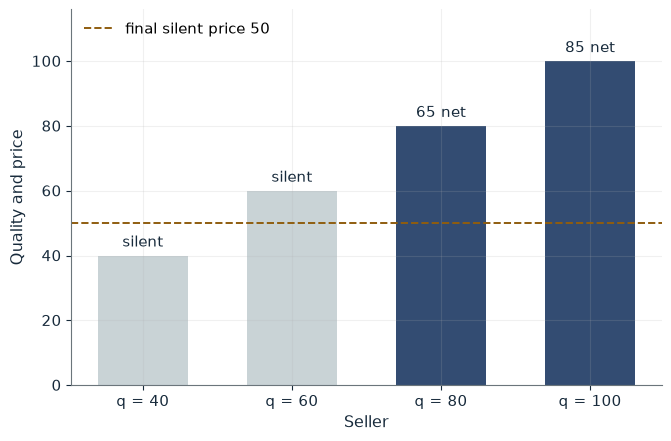

Final silent price  50
Disclosing types    100 and 80
Silent types        40 and 60

Worked steps:
  1. Silent price 70; 100 - 15 = 85 > 70, so 100 discloses
  2. Silent price 60; 80 - 15 = 65 > 60, so 80 discloses
  3. Silent price 50; 60 - 15 = 45 < 50, so 60 stays silent

With a fee of 15: Silent price 70; 100 - 15 = 85 > 70, so 100 discloses; Silent price 60; 80 - 15 = 65 > 60, so 80 discloses; Silent price 50; 60 - 15 = 45 < 50, so 60 stays silent. The process stops with 40 and 60 silent at a price of 50.


In [6]:
show(disclosure_picture(fee=15))

Change one input, `fee`, and hold the others at the book's values:

In [7]:
sweep(disclosure_picture, 'fee', [0, 5, 15, 25], {}, ['Final silent price', 'Disclosing types', 'Silent types'])

fee | Final silent price | Disclosing types | Silent types
0 | 40 | 100, 80 and 60 | 40
5 | 40 | 100, 80 and 60 | 40
15 | 50 | 100 and 80 | 40 and 60
25 | 60 | 100 | 40, 60 and 80


Without a fee everyone above 40 discloses and 40 is indifferent. A fee of 15 stops the cascade with 40 and 60 silent at 50; a fee of 25 stops it after 100.

## 4. Grossman-Stiglitz impossibility

$$0.75(\$10)+0.25(\$30)=\$15, \qquad 0.975(\$1)+0.025(\$39)=\$1.95<\$2$$

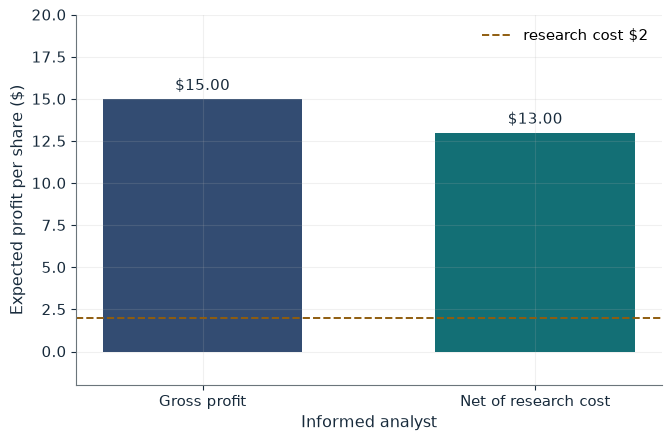

Prices               110 and 90
Gross profit         $15.00
Net profit           $13.00
Research worthwhile  yes

Worked steps:
  1. Prices: 110 and 90
  2. Gross = 0.750(10) + 0.250(30) = 15.00
  3. Net = 15.00 - 2 = 13.00

Prices are 0.750(120) + 0.250(80) = 110 and 0.750(80) + 0.250(120) = 90. In the high state the analyst buys and earns 120 - 110 = 10 with probability 0.750 or 120 - 90 = 30 with probability 0.250: 0.750(10) + 0.250(30) = 15.00. Net of the 2 cost: 13.00. Research is worthwhile.


In [8]:
show(gs_picture(pi=0.75))

Change one input, `pi`, and hold the others at the book's values:

In [9]:
sweep(gs_picture, 'pi', [0.75, 0.9, 0.975], {}, ['Prices', 'Gross profit', 'Net profit'])

pi | Prices | Gross profit | Net profit
0.75 | 110 and 90 | $15.00 | $13.00
0.9 | 116 and 84 | $7.20 | $5.20
0.975 | 119 and 81 | $1.95 | -$0.05


Gross profit is 80 pi(1 - pi): \$15 at 0.75, \$7.20 at 0.90 and \$1.95 at 0.975, below the \$2 research cost.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

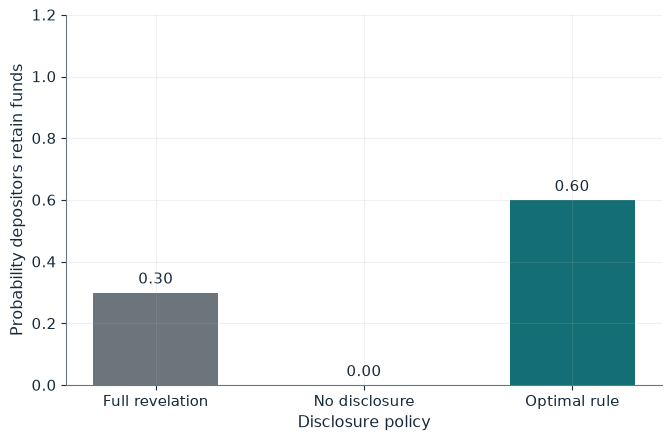

Pooling probability x       0.4286
Retention, optimal rule     0.6000
Retention, full revelation  0.30
Retention, no disclosure    0

Worked steps:
  1. x = 0.30(0.50) / (0.50 x 0.70) = 0.4286
  2. Retention = 0.30 + 0.70(0.42857) = 0.6000
  3. Check: 0.6000(0.50) + 0.4000(0) = 0.3000

Under no disclosure the posterior stays at 0.30, so everyone withdraws. Setting 0.30 / (0.30 + 0.70x) = 0.50 gives x = 0.30(0.50) / (0.50 x 0.70) = 0.4286. The retain message is sent with probability 0.30 + 0.70(0.42857) = 0.6000, against 0.30 under full revelation. Bayes plausibility: 0.6000(0.50) + 0.4000(0) = 0.3000.


In [10]:
show(persuasion_picture(threshold=0.5, prior=0.3))

## Practice

**1.** If depositors demand 0.75, what is the pooling probability and retention?

<details><summary>Answer</summary>

x = 0.30(0.25) / (0.75 x 0.70) = 1/7 and retention 0.30 + 0.70/7 = 0.40.

</details>

**2.** With b = 0.20, what actions follow each message?

<details><summary>Answer</summary>

t = (1 - 0.80) / 2 = 0.10, a_L = 0.05, a_H = 0.55.

</details>

**3.** At pi = 0.90, is research worthwhile?

<details><summary>Answer</summary>

Prices 116 and 84; gross 0.90(4) + 0.10(36) = 7.20; net 5.20 > 0, yes.

</details>